In [1]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from src import Questions


plt.rcParams.update({'font.size': 14})


In [2]:
# creating a dataframe of all of the annotator profiles
EXCLUDED_SCORES = ["2_13", "23_", "24_", "25_", "27_"]
EXCLUDED_WHOLE = [23, 24, 25, 27]
questions = Questions().get_questions()
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)


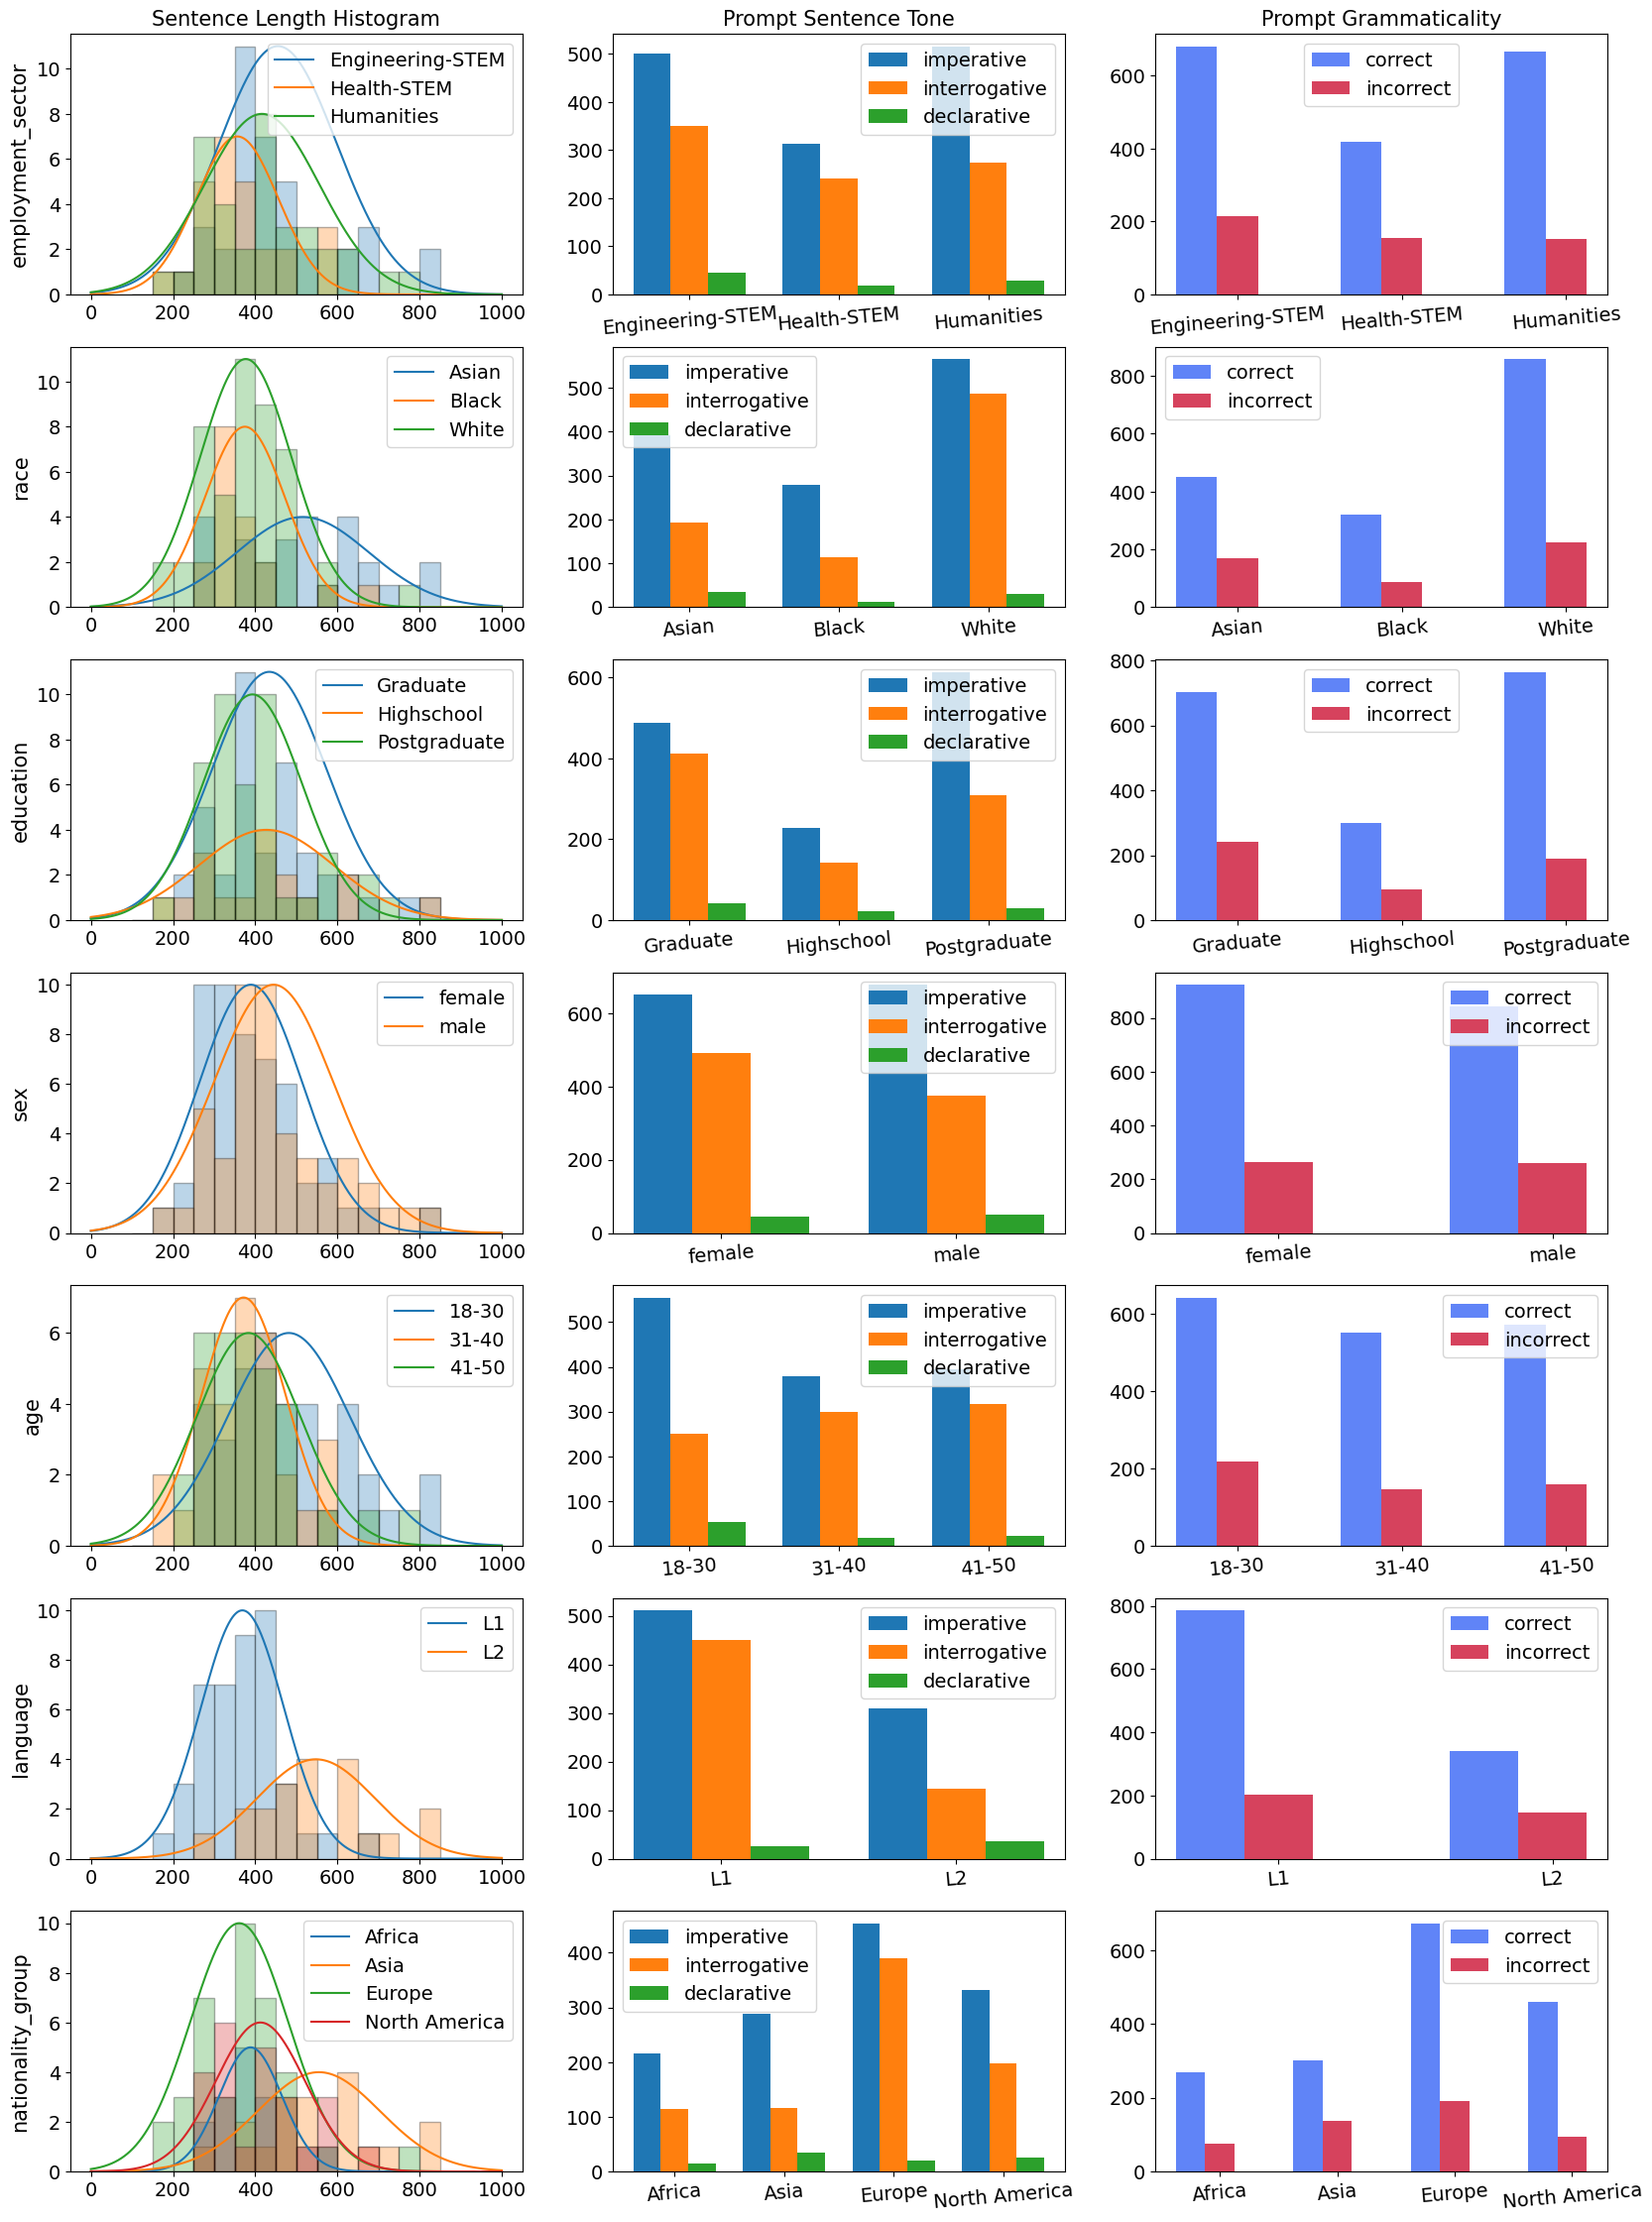

In [3]:
from src.utils.viz_utils import plot_histogram_by_category, plot_grouped_bar_chart

# making a df that has info: sum sentence length, freq count for each of the annotators
df_ptype_freqtable = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)
    
    prompt_lengths = []
    prompt_tone_freq_table = {
        "imperative" : 0,
        "interrogative" : 0,
        "declarative" : 0,
    }
    prompt_grammar_freq_table = {
        "correct" : 0,
        "incorrect" : 0,
    }
    
    for i, (question, v) in enumerate(annotator_object["answers"].items()):
        if i not in EXCLUDED_WHOLE :
            if v["answer"]:
                prompt_lengths.append(v["sentence_length"])
                prompt_tone_freq_table[v["sentence_type"]] += 1
                prompt_grammar_freq_table[v["grammaticality"]] += 1

    df_ptype_freqtable.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        "sum_prompt_lengths" : sum(prompt_lengths),
        **prompt_tone_freq_table,
        **prompt_grammar_freq_table
    })

df_ptype_freqtable = sorted(df_ptype_freqtable, key=lambda x: x["id"])
df_ptype_freqtable = pd.DataFrame(df_ptype_freqtable)


aggregates = {}
PROFILE_COLUMNS = ["employment_sector", "race", "education", "sex", "age", "language", "nationality_group"]
for pc in PROFILE_COLUMNS:
    aggregates[pc] = {}
    for demo_label_name, group_df in df_ptype_freqtable.groupby(pc):
        
        demo_label_plengths = group_df["sum_prompt_lengths"].to_list()
        
        tone_ftable = group_df[['imperative', 'interrogative', 'declarative']]
        tone_sums = tone_ftable.sum().to_dict()

        grammar_ftable = group_df[['correct', 'incorrect']]
        grammar_sums = grammar_ftable.sum().to_dict()

        group_stats = {
            "Prompt Lengths" : demo_label_plengths,
            "Prompt Tone" : tone_sums,
            "Prompt Grammar" : grammar_sums,
        }

        aggregates[pc][demo_label_name] = group_stats
# # visualizing
N = len(PROFILE_COLUMNS)
fig, axes = plt.subplots(N, 3, figsize=(20, 4 * N))

LABELSIZE=15

# Column labels
column_labels = ['Sentence Length Histogram', 'Prompt Sentence Tone', 'Prompt Grammaticality']
for col, label in enumerate(column_labels):
    axes[0, col].set_title(label, fontsize=LABELSIZE)

# Row labels
for row, label in enumerate(PROFILE_COLUMNS):
    axes[row, 0].set_ylabel(label, fontsize=LABELSIZE, rotation=90)

nrows, ncols = axes.shape
for i, j in np.ndindex(nrows, ncols):
    ax = axes[i, j]
    demo_profile = PROFILE_COLUMNS[i]
    demo_data = aggregates[demo_profile]
    if j == 0:
        data = {k : v["Prompt Lengths"] for k, v in demo_data.items()}
        plot_histogram_by_category(data, ax)
    elif j == 1:
        data = {k : v["Prompt Tone"] for k, v in demo_data.items()}
        plot_grouped_bar_chart(data, ax)
    else:
        data = {k : v["Prompt Grammar"] for k, v in demo_data.items()}
        plot_grouped_bar_chart(data, ax)

In [4]:
aggregates['employment_sector']['Engineering-STEM']

{'Prompt Lengths': [372,
  393,
  689,
  388,
  443,
  418,
  385,
  228,
  512,
  384,
  830,
  428,
  472,
  687,
  632,
  838,
  278,
  439,
  376,
  649,
  522,
  447,
  265,
  412,
  450,
  371,
  376,
  430,
  333,
  393,
  325,
  484,
  377,
  252,
  676,
  476,
  374,
  494],
 'Prompt Tone': {'imperative': 501, 'interrogative': 350, 'declarative': 46},
 'Prompt Grammar': {'correct': 681, 'incorrect': 216}}

In [5]:
df_ptype_freqtable

,id,employment_sector,race,education,sex,age,language,nationality_group,sum_prompt_lengths,imperative,interrogative,declarative,correct,incorrect
0,0,Humanities,White,Graduate,female,31-40,L1,North America,290,17,6,0,22,1
1,1,Humanities,Asian,Postgraduate,female,18-30,None,North America,269,20,1,0,19,2
2,2,Humanities,White,Graduate,female,18-30,None,North America,563,19,5,0,19,5
3,3,Engineering-STEM,White,Graduate,female,31-40,L1,Europe,372,6,19,0,17,8
4,4,Humanities,White,Graduate,female,41-50,L1,North America,424,16,9,0,23,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,100,Engineering-STEM,White,Graduate,male,41-50,None,North America,476,19,4,0,19,4
95,101,Health-STEM,Black,Postgraduate,female,41-50,L1,North America,342,15,9,0,19,5
96,103,Engineering-STEM,White,Graduate,male,41-50,L1,Europe,374,4,19,0,19,4
97,104,Engineering-STEM,White,Graduate,male,41-50,L1,North America,494,11,6,4,17,4


In [6]:

df_list = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)

    task_group_stats = {}
    task_types = ['mt_and_summarization', 'syntaxes', 'knowledge_and_reasoning', 'semantics', 'qa_extraction']
    for tt in task_types:
        prompt_lengths = []
        prompt_type_freq_table = {
            f"{tt}-imperative" : 0,
            f"{tt}-interrogative" : 0,
            f"{tt}-declarative" : 0,
        }
        prompt_grammaticality = {
            f"{tt}-grammar_correct" : 0,
            f"{tt}-grammar_incorrect" : 0,
        }
        for qi, (q, v) in enumerate(annotator_object["answers"].items()):
            if qi not in EXCLUDED_WHOLE:
                if v["answer"] and questions[q]['question_type'] == tt:
                    prompt_lengths.append(v["sentence_length"])
                    prompt_type_freq_table[f"{tt}-{v["sentence_type"]}"] += 1
                    prompt_grammaticality[f"{tt}-grammar_{v["grammaticality"]}"] += 1
        
        task_group_stats[f"{tt}-avg_sentence_lengths"] = sum(prompt_lengths)/len(prompt_lengths) if len(prompt_lengths) > 0 else 0
        task_group_stats.update(prompt_type_freq_table)
        task_group_stats.update(prompt_grammaticality)

    df_list.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        **task_group_stats
    })

df_list = sorted(df_list, key=lambda x: x["id"])
df = pd.DataFrame(df_list)

In [7]:
df

,id,employment_sector,race,education,sex,age,language,nationality_group,mt_and_summarization-avg_sentence_lengths,mt_and_summarization-imperative,...,semantics-interrogative,semantics-declarative,semantics-grammar_correct,semantics-grammar_incorrect,qa_extraction-avg_sentence_lengths,qa_extraction-imperative,qa_extraction-interrogative,qa_extraction-declarative,qa_extraction-grammar_correct,qa_extraction-grammar_incorrect
0,0,Humanities,White,Graduate,female,31-40,L1,North America,4.0,2,...,0,0,3,0,10.000000,2,0,0,2,0
1,1,Humanities,Asian,Postgraduate,female,18-30,None,North America,2.5,2,...,0,0,1,0,13.333333,3,0,0,3,0
2,2,Humanities,White,Graduate,female,18-30,None,North America,7.0,2,...,3,0,2,1,17.333333,2,1,0,2,1
3,3,Engineering-STEM,White,Graduate,female,31-40,L1,Europe,9.0,1,...,3,0,2,1,5.000000,2,1,0,2,1
4,4,Humanities,White,Graduate,female,41-50,L1,North America,5.0,2,...,3,0,3,0,20.666667,2,1,0,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,100,Engineering-STEM,White,Graduate,male,41-50,None,North America,10.0,1,...,0,0,2,1,30.000000,3,0,0,3,0
95,101,Health-STEM,Black,Postgraduate,female,41-50,L1,North America,2.5,2,...,1,0,1,2,19.000000,2,1,0,3,0
96,103,Engineering-STEM,White,Graduate,male,41-50,L1,Europe,5.0,0,...,2,0,2,0,16.000000,1,1,0,2,0
97,104,Engineering-STEM,White,Graduate,male,41-50,L1,North America,9.5,1,...,0,2,2,1,0.000000,0,0,0,0,0


In [8]:
question_type_df = []
for iq, qv in enumerate(questions.values()):
    if iq not in EXCLUDED_WHOLE:
        question_type_df.append({
            "Task Name": qv['nickname'],
            "Task Type": qv['question_type'],
        })

question_type_df = pd.DataFrame(question_type_df)
question_type_df = question_type_df.sort_values(by='Task Type')
question_type_df.columns = question_type_df.columns.str.replace('_', r'\_', regex=False)
question_type_df = question_type_df.replace('_', r'\_', regex=True)
print(question_type_df.to_latex(index=False, escape=False))

\begin{tabular}{ll}
\toprule
Task Name & Task Type \\
\midrule
Free Generation: School Life & knowledge\_and\_reasoning \\
Free Generation: Arithmetic & knowledge\_and\_reasoning \\
Free Generation: MBZUAI & knowledge\_and\_reasoning \\
Free Generation: Hillary Clinton & knowledge\_and\_reasoning \\
Free Generation: Olympics Medallists & knowledge\_and\_reasoning \\
Free Generation: Scientific Letter & knowledge\_and\_reasoning \\
Free Generation: Giant Drum & knowledge\_and\_reasoning \\
Free Generation: Karak Kaliang & knowledge\_and\_reasoning \\
Linguistically-conditioned Text Generation & knowledge\_and\_reasoning \\
Free Generation: Hijrah & knowledge\_and\_reasoning \\
Free Generation: G30SPKI & knowledge\_and\_reasoning \\
Free Generation: Balonku Song & knowledge\_and\_reasoning \\
Free Generation: Adhan & knowledge\_and\_reasoning \\
Dialogue Summarization & mt\_and\_summarization \\
Machine Translation & mt\_and\_summarization \\
Multiple Choice Questions & qa\_extraction \\

In [9]:
df

,id,employment_sector,race,education,sex,age,language,nationality_group,mt_and_summarization-avg_sentence_lengths,mt_and_summarization-imperative,...,semantics-interrogative,semantics-declarative,semantics-grammar_correct,semantics-grammar_incorrect,qa_extraction-avg_sentence_lengths,qa_extraction-imperative,qa_extraction-interrogative,qa_extraction-declarative,qa_extraction-grammar_correct,qa_extraction-grammar_incorrect
0,0,Humanities,White,Graduate,female,31-40,L1,North America,4.0,2,...,0,0,3,0,10.000000,2,0,0,2,0
1,1,Humanities,Asian,Postgraduate,female,18-30,None,North America,2.5,2,...,0,0,1,0,13.333333,3,0,0,3,0
2,2,Humanities,White,Graduate,female,18-30,None,North America,7.0,2,...,3,0,2,1,17.333333,2,1,0,2,1
3,3,Engineering-STEM,White,Graduate,female,31-40,L1,Europe,9.0,1,...,3,0,2,1,5.000000,2,1,0,2,1
4,4,Humanities,White,Graduate,female,41-50,L1,North America,5.0,2,...,3,0,3,0,20.666667,2,1,0,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,100,Engineering-STEM,White,Graduate,male,41-50,None,North America,10.0,1,...,0,0,2,1,30.000000,3,0,0,3,0
95,101,Health-STEM,Black,Postgraduate,female,41-50,L1,North America,2.5,2,...,1,0,1,2,19.000000,2,1,0,3,0
96,103,Engineering-STEM,White,Graduate,male,41-50,L1,Europe,5.0,0,...,2,0,2,0,16.000000,1,1,0,2,0
97,104,Engineering-STEM,White,Graduate,male,41-50,L1,North America,9.5,1,...,0,2,2,1,0.000000,0,0,0,0,0


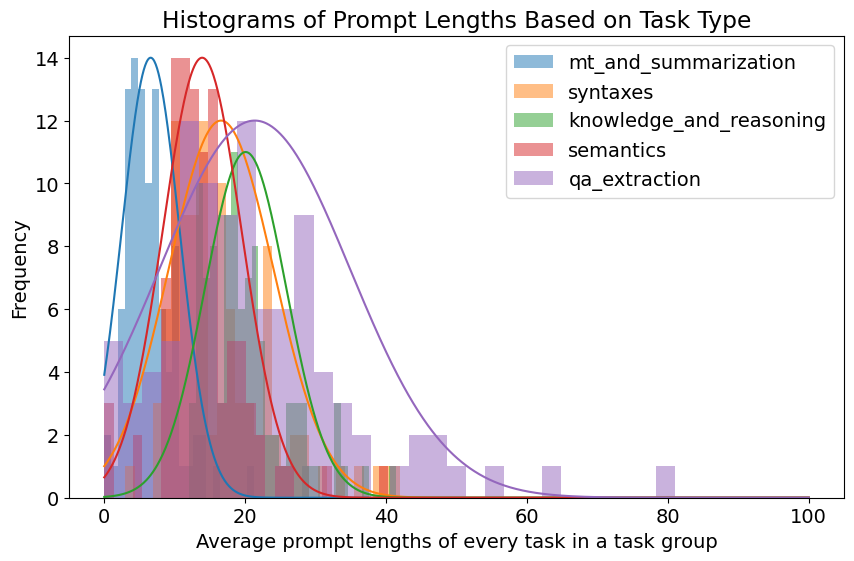

In [10]:
# for prompt length make histogram of 5 task types overlay each other
cols = df.columns[df.columns.str.contains("avg_sentence_lengths")]
plt.figure(figsize=(10, 6))

for col in cols:
    values = df[col].dropna()
    counts, bin_edges, _ = plt.hist(values, bins=30, alpha=0.5, label=col.replace("-avg_sentence_lengths", "").strip())

    mu, std = np.mean(values), np.std(values)
    x = np.linspace(0, 100, 1000)
    p = norm.pdf(x, mu, std)
    scale = max(counts) / np.max(p)

    # Get the current color used for the histogram
    color = plt.gca().patches[-1].get_facecolor()
    plt.plot(x, p * scale, color=color, alpha=1)

plt.legend()
plt.xlabel('Average prompt lengths of every task in a task group')
plt.ylabel('Frequency')
plt.title('Histograms of Prompt Lengths Based on Task Type')
plt.show()

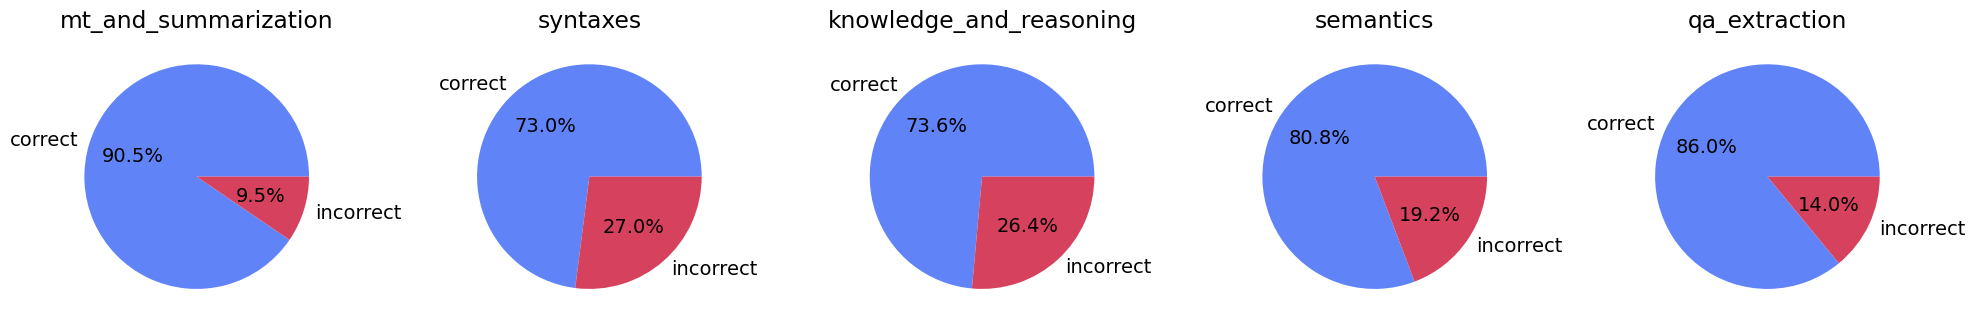

In [11]:
colors = ['#6084f7', '#d6425d']
keywords = ["grammar_correct", "grammar_incorrect"]
pattern = "|".join(keywords)
cols = df.columns[df.columns.str.contains(pattern)]
s = df[cols].sum(axis=0)

# Group the data by prefix
grouped = {}
for k, v in s.items():
    prefix, label = k.split('-', 1)
    grouped.setdefault(prefix, {})[label] = v

# One row of pie charts
n = len(grouped)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))

for ax, (prefix, data) in zip(axes, grouped.items()):
    ax.pie(data.values(), labels=[d.replace("grammar_", "") for d in data.keys()], autopct='%1.1f%%', colors=colors)
    ax.set_title(prefix)

plt.tight_layout()
plt.show()

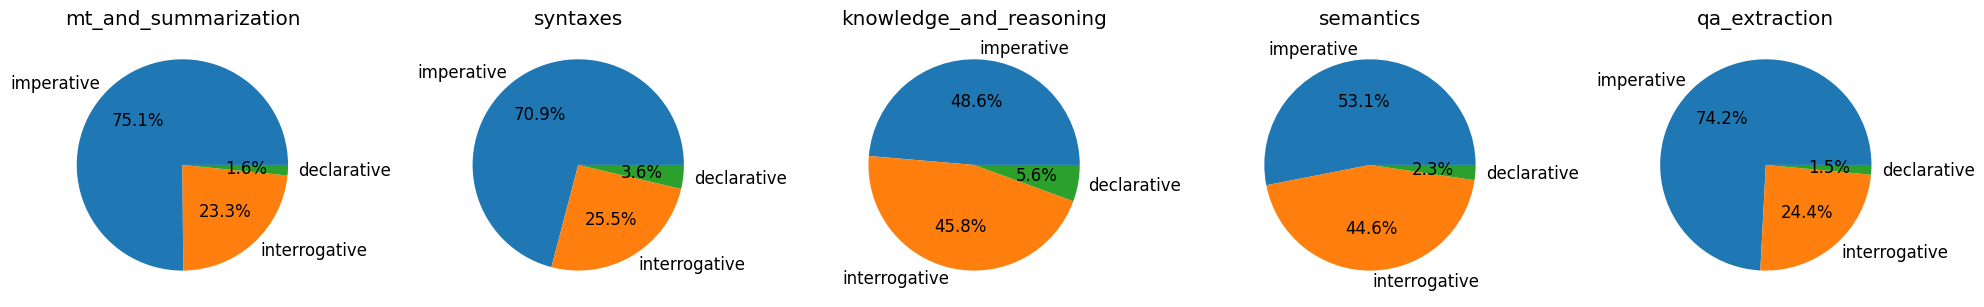

In [12]:

plt.rcParams.update({'font.size': 12})
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
keywords = ["imperative", "interrogative", "declarative"]
pattern = "|".join(keywords)
cols = df.columns[df.columns.str.contains(pattern)]
s = df[cols].sum(axis=0)

# Group the data by prefix
grouped = {}
for k, v in s.items():
    prefix, label = k.split('-', 1)
    grouped.setdefault(prefix, {})[label] = v

# One row of pie charts
n = len(grouped)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))

for ax, (prefix, data) in zip(axes, grouped.items()):
    ax.pie(data.values(), labels=data.keys(), autopct='%1.1f%%', colors=colors)
    ax.set_title(prefix)

plt.tight_layout()
plt.show()

In [13]:
# aggregates = {
#     "sum_sentence_lengths": {
#         "employment_sector" : [...],
#         "race" : [...],
#         "education" : [...],
#     },
#     "interrogative",
#     imperative	interrogative	declarative	grammar_correct	grammar_incorrect
# }
# aggregates:

profile_columns = ["employment_sector", "race", "education", "sex", "age", "language", "nationality_group"]
for pc in profile_columns:
    for group_value, group_df in df.groupby(pc):
        print(f"\nGroup: {pc} = {group_value}")
        print(f"Group members = {len(group_df)}")
        others = [col for col in profile_columns if col != pc]
        for oc in others:
            top_value = group_df[oc].value_counts(normalize=True).idxmax()
            top_ratio = group_df[oc].value_counts(normalize=True).max()
            if top_ratio > 0.5:
                print(f"  Column {oc} dominated by '{top_value}' with {top_ratio:.2f}")


Group: employment_sector = Engineering-STEM
Group members = 38
  Column sex dominated by 'male' with 0.58
  Column language dominated by 'L1' with 0.57

Group: employment_sector = Health-STEM
Group members = 26
  Column race dominated by 'White' with 0.60
  Column education dominated by 'Postgraduate' with 0.58
  Column sex dominated by 'female' with 0.73
  Column language dominated by 'L1' with 1.00

Group: employment_sector = Humanities
Group members = 35
  Column race dominated by 'White' with 0.52
  Column sex dominated by 'male' with 0.51
  Column language dominated by 'L1' with 0.59

Group: race = Asian
Group members = 26
  Column employment_sector dominated by 'Engineering-STEM' with 0.58
  Column sex dominated by 'male' with 0.65
  Column age dominated by '18-30' with 0.85
  Column language dominated by 'L2' with 0.87
  Column nationality_group dominated by 'Asia' with 0.72

Group: race = Black
Group members = 18
  Column education dominated by 'Postgraduate' with 0.89
  Colum